# Practical Application III — Comparing Classifiers
## Required Assignment 17.1 | Bank Term-Deposit Marketing

**Business objective:** Rank prospective contacts by their likelihood of subscribing to a term deposit, using information available **before** a marketing call. Compare Logistic Regression, K-Nearest Neighbors, Decision Tree, and Support Vector Machine using consistent validation and business-relevant metrics.

**Method:** CRISP-DM (business understanding → data understanding → preparation → modeling → evaluation → deployment recommendations). This notebook follows the instructor's Problems 1–11. Source: the instructor-provided `module17_starter` data files.

**Important:** These are historical observational campaign records. Predictions are not proof of causation, and they should not be used as automated decisions about customers.

## Setup and reproducibility
Run the notebook from `notebooks/` or the project root. All outputs are written under `outputs/`. The full dataset is the primary analysis source; no separate UCI download is required.

In [1]:
from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance
warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
ROOT = next((p for p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent)
             if (p / 'data' / 'bank-additional-full.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Cannot locate data/bank-additional-full.csv. Keep the project folder structure intact.')
FIG, REP = ROOT / 'outputs' / 'figures', ROOT / 'outputs' / 'reports'
FIG.mkdir(parents=True, exist_ok=True)
REP.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
print('Project root:', ROOT)

Project root: /mnt/data/Module_17/Assignment_17_1_Comparing_Classifiers


## 1. Business Understanding
### Problem 1: Understanding the Data
The dataset records outcomes of Portuguese bank telephone campaigns. A successful outcome is `y = yes`, indicating a term-deposit subscription. Campaign managers want to identify more promising contacts while reducing unnecessary calls. The accompanying CRISP-DM reference explains this efficiency objective.

**Success criteria:** compare out-of-sample discrimination and precision/recall; prioritize customers at a fixed outreach capacity (top 10% of ranked contacts); compare training time and model interpretability. A predictive model is not yet a validated production targeting policy.

## 2. Data Understanding
### Problem 2: Read in the Data
The supplied CSV is semicolon-delimited. The full file is used for the primary analysis.

In [2]:
df = pd.read_csv(ROOT / 'data' / 'bank-additional-full.csv', sep=';')
print('Original dataset shape:', df.shape)
display(df.head(5))
print('Target counts:')
display(df['y'].value_counts().rename_axis('subscription').to_frame('records'))

Original dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Target counts:


,records
subscription,
no,36548
yes,4640


### Problem 3: Understanding the Features
Categorical `unknown` values represent missing/unspecified information and are retained as explicit categories rather than silently discarded. `pdays = 999` means no prior contact, not 999 elapsed days. `duration` is known only after the call, so it is excluded from pre-call prediction. Some fields (e.g., month/day of contact) may only be available once scheduling decisions are made; deployment must respect the actual scoring time.

In [3]:
summary = pd.DataFrame({'dtype': df.dtypes.astype(str),
    'null_count': df.isna().sum(),
    'unknown_count': [(df[c].astype(str).str.lower() == 'unknown').sum() if df[c].dtype == 'object' else 0 for c in df.columns],
    'unique_values': df.nunique()})
display(summary)
summary.to_csv(REP / 'data_quality_summary.csv', index_label='feature')
print('Duplicate rows:', df.duplicated().sum())
print('Target subscription rate:', f"{df['y'].eq('yes').mean():.1%}")

,dtype,null_count,unknown_count,unique_values
age,int64,0,0,78
job,object,0,330,12
marital,object,0,80,4
education,object,0,1731,8
default,object,0,8597,3
housing,object,0,990,3
loan,object,0,990,3
contact,object,0,0,2
month,object,0,0,10
day_of_week,object,0,0,5


Duplicate rows: 12
Target subscription rate: 11.3%


### Exploratory Data Analysis — Descriptive Statistics
We use a count plot for the categorical target, box plots for numerical age, and grouped categorical subscription rates. These are **descriptive associations**, not causal effects. The 95% Wilson confidence interval below describes sampling uncertainty under an independent-sampling assumption; repeated customers and campaign time effects may violate that assumption.

In [4]:
from statsmodels.stats.proportion import proportion_confint
n_yes = int(df['y'].eq('yes').sum())
ci_low, ci_high = proportion_confint(n_yes, len(df), alpha=0.05, method='wilson')
print(f'Subscription rate: {n_yes/len(df):.2%} (95% Wilson CI: {ci_low:.2%}–{ci_high:.2%})')
print('Numerical feature summary:')
display(df.select_dtypes(include='number').describe().T.round(2))

Subscription rate: 11.27% (95% Wilson CI: 10.96%–11.57%)
Numerical feature summary:


,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


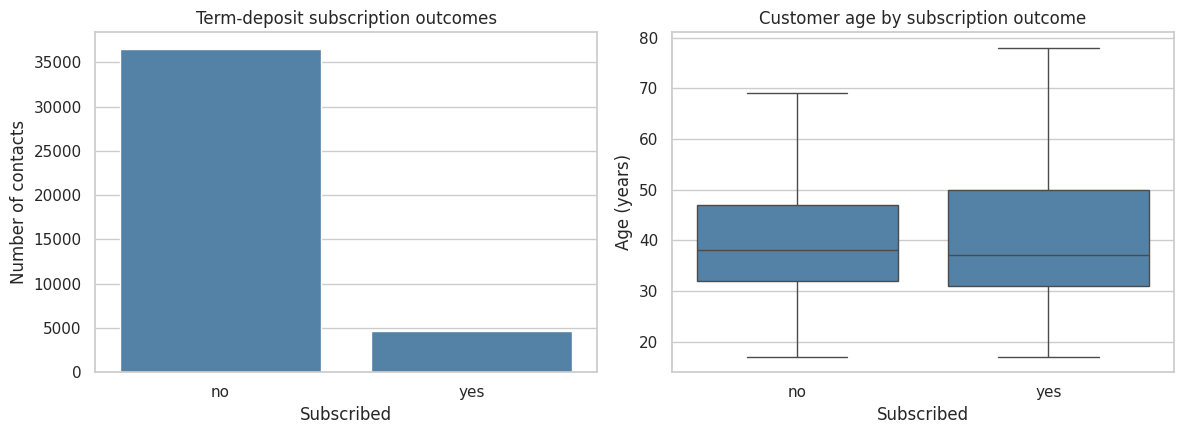

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(data=df, x='y', order=['no', 'yes'], color='steelblue', ax=axes[0])
axes[0].set(title='Term-deposit subscription outcomes', xlabel='Subscribed', ylabel='Number of contacts')
sns.boxplot(data=df, x='y', y='age', order=['no', 'yes'], showfliers=False, color='steelblue', ax=axes[1])
axes[1].set(title='Customer age by subscription outcome', xlabel='Subscribed', ylabel='Age (years)')
fig.tight_layout(); fig.savefig(FIG / 'target_and_age.png', dpi=150); plt.show()

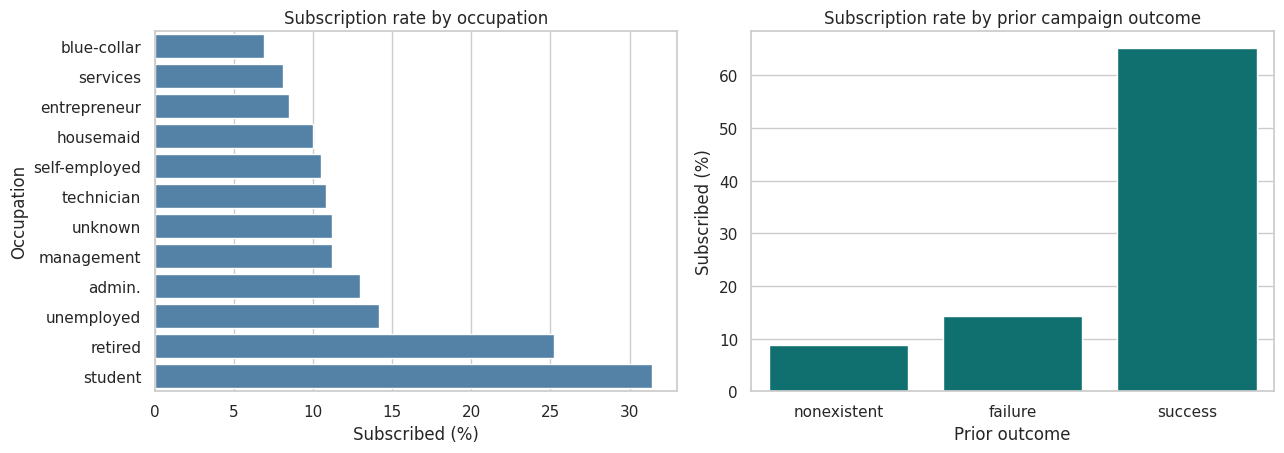

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
job_rate = df.groupby('job')['y'].apply(lambda s: s.eq('yes').mean()).sort_values()
sns.barplot(x=job_rate.values * 100, y=job_rate.index, ax=axes[0], color='steelblue')
axes[0].set(title='Subscription rate by occupation', xlabel='Subscribed (%)', ylabel='Occupation')
prior_rate = df.groupby('poutcome')['y'].apply(lambda s: s.eq('yes').mean()).sort_values()
sns.barplot(x=prior_rate.index, y=prior_rate.values * 100, ax=axes[1], color='teal')
axes[1].set(title='Subscription rate by prior campaign outcome', xlabel='Prior outcome', ylabel='Subscribed (%)')
fig.tight_layout(); fig.savefig(FIG / 'categorical_subscription_rates.png', dpi=150); plt.show()
job_rate.rename('subscription_rate').to_csv(REP / 'job_subscription_rates.csv')

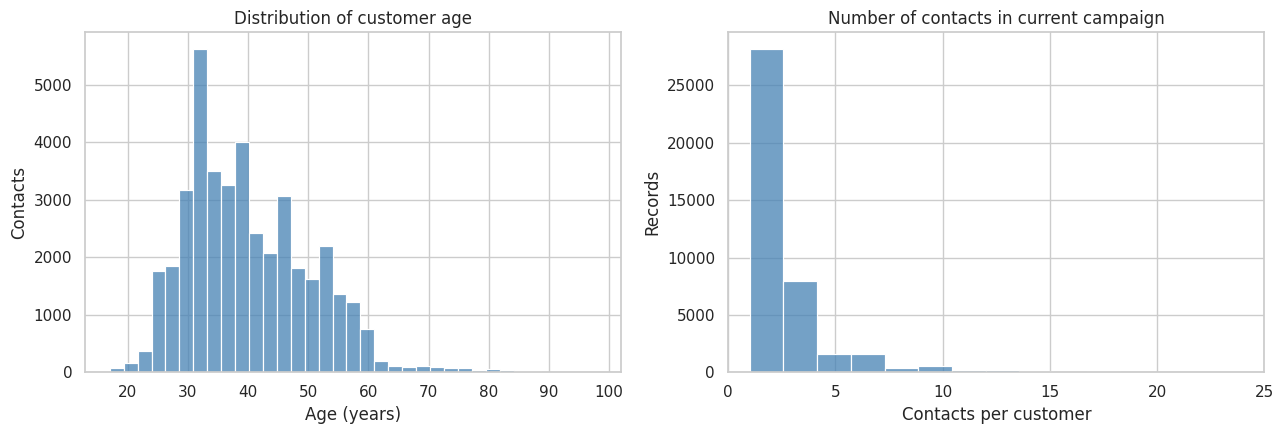

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=df, x='age', bins=35, color='steelblue', ax=axes[0])
axes[0].set(title='Distribution of customer age', xlabel='Age (years)', ylabel='Contacts')
sns.histplot(data=df, x='campaign', bins=35, color='steelblue', ax=axes[1])
axes[1].set(title='Number of contacts in current campaign', xlabel='Contacts per customer', ylabel='Records')
axes[1].set_xlim(0, min(25, df['campaign'].max()))
fig.tight_layout(); fig.savefig(FIG / 'numeric_distributions.png', dpi=150); plt.show()

## 3. Data Preparation
### Problem 4: Understanding the Task
**Task:** binary classification, `yes` = 1 and `no` = 0. We use only pre-call information and remove `duration` to prevent post-outcome leakage. We preserve the original records rather than deleting `unknown` categories. The historical data may contain repeated customers, but no unique customer identifier is available for grouped splitting.

In [8]:
X = df.drop(columns=['y', 'duration']).copy()
y = df['y'].map({'no': 0, 'yes': 1}).astype(int)
assert y.notna().all()
print('Predictors:', X.shape[1], '| Positive cases:', y.sum(), '| Positive rate:', f'{y.mean():.2%}')

Predictors: 19 | Positive cases: 4640 | Positive rate: 11.27%


### Problem 5: Engineering Features
Impute numeric values with the training-fold median; standardize numeric features for distance- and margin-based classifiers. One-hot encode categorical features, retaining `unknown` as an informative label. All transformations are fitted **inside** the training/CV pipeline to avoid leakage.

In [9]:
numeric_features = X.select_dtypes(include='number').columns.tolist()
categorical_features = X.select_dtypes(exclude='number').columns.tolist()
numeric_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')),
                         ('scaler', StandardScaler())])
categorical_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                             ('onehot', OneHotEncoder(handle_unknown='ignore'))])
preprocessor = ColumnTransformer([('num', numeric_pipe, numeric_features),
                                  ('cat', categorical_pipe, categorical_features)])
print('Numeric:', numeric_features)
print('Categorical:', categorical_features)

Numeric: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


### Problem 6: Train/Test Split
Use an 80/20 stratified split, preserving the minority subscription rate. Keep the test set untouched until model selection and tuning are complete. Three-fold stratified cross-validation is used on the training data.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Positive rates:', round(y_train.mean(), 4), round(y_test.mean(), 4))

Train: (32950, 19) Test: (8238, 19)
Positive rates: 0.1127 0.1126


## 4. Modeling
### Problem 7: A Baseline Model
A majority-class classifier can have high accuracy on this imbalanced dataset while finding no subscribers. The baseline establishes why accuracy alone is inadequate.

**Primary metric:** Average Precision (AP, area under the precision–recall curve), because subscriptions are relatively uncommon and the bank wants a useful ranking of promising contacts. **Secondary metrics:** ROC-AUC, precision, recall, F1, accuracy, and fit time. AP is threshold-independent but depends on class prevalence.

In [11]:
baseline = DummyClassifier(strategy='prior')
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_test)
base_score = baseline.predict_proba(X_test)[:, 1]
print('Baseline accuracy:', round(accuracy_score(y_test, base_pred), 4))
print('Baseline average precision:', round(average_precision_score(y_test, base_score), 4))

Baseline accuracy: 0.8874
Baseline average precision: 0.1126


### Problem 8: A Simple Model
Fit Logistic Regression with a preprocessing pipeline. Its coefficients are interpretable as changes in **log odds**, conditional on other encoded features; they are not causal effects.

In [12]:
simple_logistic = Pipeline([('prep', preprocessor),
                            ('model', LogisticRegression(max_iter=1500, random_state=RANDOM_STATE))])
start = time.perf_counter()
simple_logistic.fit(X_train, y_train)
print(f'Logistic Regression fit time: {time.perf_counter()-start:.1f}s')

Logistic Regression fit time: 1.3s


### Problem 9: Score the Model
Report accuracy as requested, and AP/ROC-AUC to assess discrimination under class imbalance.

In [13]:
log_pred = simple_logistic.predict(X_test)
log_score = simple_logistic.predict_proba(X_test)[:, 1]
print('Logistic accuracy:', round(accuracy_score(y_test, log_pred), 4))
print('Logistic average precision:', round(average_precision_score(y_test, log_score), 4))
print('Logistic ROC-AUC:', round(roc_auc_score(y_test, log_score), 4))

Logistic accuracy: 0.9009
Logistic average precision: 0.4648
Logistic ROC-AUC: 0.8008


### Problem 10: Model Comparisons
Compare all four classifiers with the same train/test split and preprocessing. `LinearSVC` is a **linear support vector machine**; it is faster and more practical for the full one-hot-encoded dataset than a nonlinear kernel SVC. Decision scores (not probabilities) are valid for AP and ROC-AUC.

**Runtime note:** KNN on all records may be slow; allow time for cross-validation. Model training is not sampled.

In [14]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1500, random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(n_neighbors=15, weights='distance'),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, min_samples_leaf=30, random_state=RANDOM_STATE),
    'Linear SVM': LinearSVC(C=1.0, dual=False, max_iter=4000, random_state=RANDOM_STATE),
}

def get_scores(fitted_pipeline, features):
    if hasattr(fitted_pipeline, 'predict_proba'):
        return fitted_pipeline.predict_proba(features)[:, 1]
    return fitted_pipeline.decision_function(features)

def evaluate_model(name, fitted_pipeline, fit_seconds):
    preds = fitted_pipeline.predict(X_test)
    scores = get_scores(fitted_pipeline, X_test)
    return {'model': name, 'test_accuracy': accuracy_score(y_test, preds),
            'test_precision': precision_score(y_test, preds, zero_division=0),
            'test_recall': recall_score(y_test, preds, zero_division=0),
            'test_f1': f1_score(y_test, preds, zero_division=0),
            'test_average_precision': average_precision_score(y_test, scores),
            'test_roc_auc': roc_auc_score(y_test, scores),
            'fit_seconds': fit_seconds}

comparison_rows = []
fitted_models = {}
for name, estimator in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', estimator)])
    start = time.perf_counter()
    pipe.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    fitted_models[name] = pipe
    comparison_rows.append(evaluate_model(name, pipe, fit_seconds))
    print(f'{name}: fitted in {fit_seconds:.1f}s')
comparison = pd.DataFrame(comparison_rows).sort_values('test_average_precision', ascending=False)
display(comparison.round(4))
comparison.to_csv(REP / 'default_model_comparison.csv', index=False)

Logistic Regression: fitted in 1.9s


KNN: fitted in 0.1s


Decision Tree: fitted in 0.2s


Linear SVM: fitted in 0.3s


,model,test_accuracy,test_precision,test_recall,test_f1,test_average_precision,test_roc_auc,fit_seconds
0,Logistic Regression,0.9009,0.6905,0.2188,0.3322,0.4648,0.8008,1.9321
2,Decision Tree,0.9019,0.6435,0.2899,0.3997,0.4630,0.8089,0.2364
3,Linear SVM,0.9014,0.7164,0.2069,0.3211,0.4614,0.7979,0.2672
1,KNN,0.8949,0.5708,0.2694,0.3660,0.3751,0.7553,0.1455


### Problem 11: Improving the Model — Cross-validation and GridSearchCV
Tune each model using **only the training set** and **3-fold stratified CV**. Search a compact, documented grid to balance rigor and runtime. Select hyperparameters using average precision. The test set is evaluated once after each tuning search.

**Interpretation caveat:** Choosing the best model based on test scores would bias the final estimate. Choose the winner by cross-validated AP and report held-out metrics for transparency.

In [15]:
param_grids = {
    'Logistic Regression': {'model__C': [0.1, 1.0, 5.0]},
    'KNN': {'model__n_neighbors': [11, 21], 'model__weights': ['uniform', 'distance']},
    'Decision Tree': {'model__max_depth': [5, 10], 'model__min_samples_leaf': [25, 75]},
    'Linear SVM': {'model__C': [0.1, 1.0, 5.0]},
}
searches, tuned_rows = {}, []
for name, estimator in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', estimator)])
    search = GridSearchCV(pipe, param_grids[name], scoring='average_precision',
                          cv=cv, n_jobs=-1, refit=True, error_score='raise')
    start = time.perf_counter()
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    searches[name] = search
    row = evaluate_model(name, search.best_estimator_, elapsed)
    row['cv_average_precision'] = search.best_score_
    row['best_params'] = str(search.best_params_)
    tuned_rows.append(row)
    print(f'{name}: CV AP={search.best_score_:.4f}; time={elapsed:.1f}s; params={search.best_params_}')
tuned = pd.DataFrame(tuned_rows).sort_values('cv_average_precision', ascending=False)
display(tuned.round(4))
tuned.to_csv(REP / 'tuned_model_comparison.csv', index=False)

Logistic Regression: CV AP=0.4487; time=6.7s; params={'model__C': 1.0}


KNN: CV AP=0.4108; time=5.8s; params={'model__n_neighbors': 21, 'model__weights': 'uniform'}


Decision Tree: CV AP=0.4313; time=1.2s; params={'model__max_depth': 10, 'model__min_samples_leaf': 75}


Linear SVM: CV AP=0.4438; time=1.3s; params={'model__C': 0.1}


,model,test_accuracy,test_precision,test_recall,test_f1,test_average_precision,test_roc_auc,fit_seconds,cv_average_precision,best_params
0,Logistic Regression,0.9009,0.6905,0.2188,0.3322,0.4648,0.8008,6.6951,0.4487,{'model__C': 1.0}
3,Linear SVM,0.9012,0.7143,0.2047,0.3183,0.4616,0.7980,1.3009,0.4438,{'model__C': 0.1}
2,Decision Tree,0.9005,0.6534,0.2478,0.3594,0.4666,0.8065,1.2065,0.4313,"{'model__max_depth': 10, 'model__min_samples_l..."
1,KNN,0.9018,0.6776,0.2446,0.3595,0.4353,0.7765,5.7909,0.4108,"{'model__n_neighbors': 21, 'model__weights': '..."


## 5. Evaluation
### Model performance, confusion matrices, and PR curves
Average precision summarizes the precision–recall trade-off across decision thresholds. Recall is the fraction of actual subscribers identified; precision is the fraction of predicted subscribers who actually subscribed. A confusion matrix makes false positives and false negatives visible. Compare with the class-prevalence baseline.

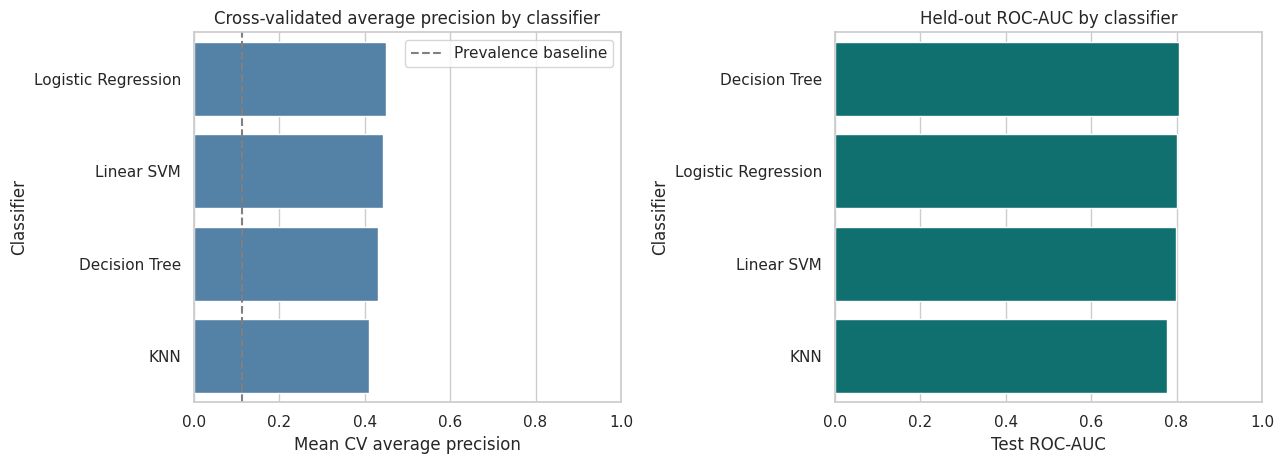

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.barplot(data=tuned.sort_values('cv_average_precision', ascending=False),
            x='cv_average_precision', y='model', ax=axes[0], color='steelblue')
axes[0].axvline(y_train.mean(), linestyle='--', color='gray', label='Prevalence baseline')
axes[0].legend()
axes[0].set(title='Cross-validated average precision by classifier', xlabel='Mean CV average precision', ylabel='Classifier', xlim=(0, 1))
sns.barplot(data=tuned.sort_values('test_roc_auc', ascending=False),
            x='test_roc_auc', y='model', ax=axes[1], color='teal')
axes[1].set(title='Held-out ROC-AUC by classifier', xlabel='Test ROC-AUC', ylabel='Classifier', xlim=(0, 1))
fig.tight_layout(); fig.savefig(FIG / 'model_comparison.png', dpi=150); plt.show()

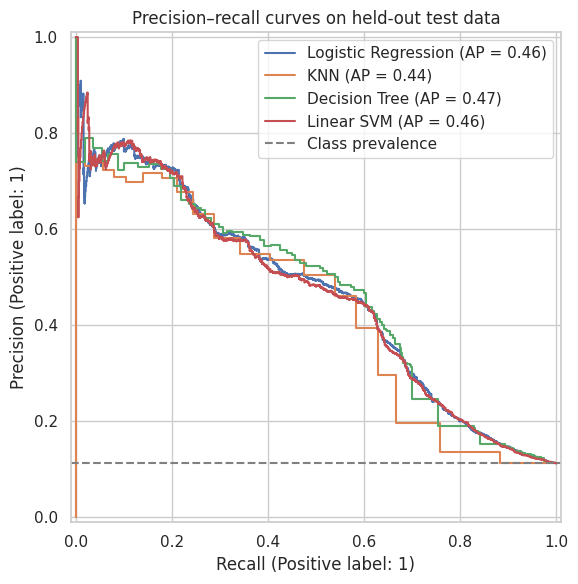

In [17]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, search in searches.items():
    PrecisionRecallDisplay.from_estimator(search.best_estimator_, X_test, y_test,
                                           name=name, ax=ax)
ax.axhline(y_test.mean(), linestyle='--', color='gray', label='Class prevalence')
ax.set(title='Precision–recall curves on held-out test data')
ax.legend(loc='upper right')
fig.tight_layout(); fig.savefig(FIG / 'precision_recall_curves.png', dpi=150); plt.show()

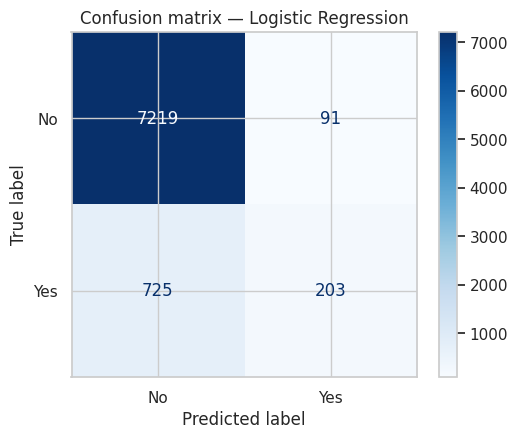

Selected by CV average precision: Logistic Regression
              precision    recall  f1-score   support

          No       0.91      0.99      0.95      7310
         Yes       0.69      0.22      0.33       928

    accuracy                           0.90      8238
   macro avg       0.80      0.60      0.64      8238
weighted avg       0.88      0.90      0.88      8238



In [18]:
winner = tuned.iloc[0]['model']  # Select by training-only CV AP, not test AP.
best_pipe = searches[winner].best_estimator_
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_estimator(best_pipe, X_test, y_test,
                                       display_labels=['No', 'Yes'], cmap='Blues', ax=ax)
ax.set_title(f'Confusion matrix — {winner}')
fig.tight_layout(); fig.savefig(FIG / 'best_model_confusion_matrix.png', dpi=150); plt.show()
print('Selected by CV average precision:', winner)
print(classification_report(y_test, best_pipe.predict(X_test), target_names=['No', 'Yes'], zero_division=0))

### Coefficient and feature interpretation
Logistic coefficients are log-odds shifts for a one-unit change in the transformed feature. Numeric features are standardized, so their coefficients correspond to a one-standard-deviation increase. One-hot categorical coefficients are relative to the other encoded categories **under the model's regularization**, not causal effects. Unlike logistic regression, KNN and nonlinear SVMs do not have directly comparable global coefficients; a linear SVM's coefficients describe the separating margin, not odds.

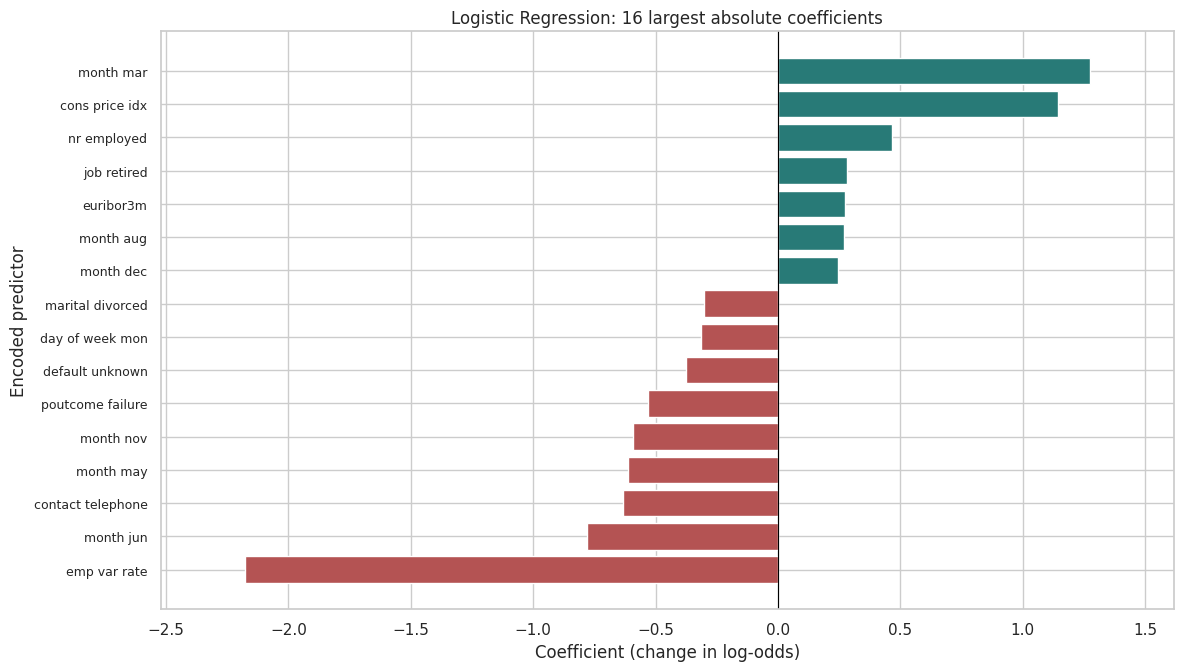

Interpretation: coefficients describe associations conditional on other predictors;
they are not causal effects. Numeric variables were standardized.


In [19]:
import textwrap
log_best = searches['Logistic Regression'].best_estimator_
feature_names = log_best.named_steps['prep'].get_feature_names_out()
coefficients = pd.Series(log_best.named_steps['model'].coef_[0], index=feature_names,
                         name='log_odds_coefficient')
coefficient_table = coefficients.to_frame().assign(odds_ratio=np.exp(coefficients))
coefficient_table.to_csv(REP / 'logistic_coefficients.csv', index_label='encoded_feature')

# Display the strongest coefficients with shorter, human-readable feature labels.
strong = coefficients.reindex(
    coefficients.abs().nlargest(16).index
).sort_values()

def readable_feature_name(encoded_name):
    """Remove transformer prefixes and wrap long category names for display."""
    label = encoded_name.split('__', 1)[-1].replace('_', ' ').replace('.', ' ')
    return textwrap.fill(label, width=28, break_long_words=False)

plot_labels = [readable_feature_name(name) for name in strong.index]
fig, ax = plt.subplots(figsize=(12, max(6.5, len(strong) * 0.43)))
colors = ['#b45353' if value < 0 else '#287a77' for value in strong.values]
ax.barh(plot_labels, strong.values, color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set(title='Logistic Regression: 16 largest absolute coefficients',
       xlabel='Coefficient (change in log-odds)', ylabel='Encoded predictor')
ax.tick_params(axis='y', labelsize=9)
ax.margins(x=0.10)
fig.tight_layout()
fig.savefig(FIG / 'logistic_coefficients.png', dpi=170, bbox_inches='tight')
plt.show()
print('Interpretation: coefficients describe associations conditional on other predictors;')
print('they are not causal effects. Numeric variables were standardized.')

### Campaign targeting: top-decile lift
At a fixed outreach capacity, rank contacts by model score. **Top-decile lift** is the subscription rate among the highest-scoring 10% divided by the overall test subscription rate. This is a descriptive offline targeting measure; actual campaign performance requires prospective testing.

In [20]:
scores = get_scores(best_pipe, X_test)
ranked = pd.DataFrame({'score': scores, 'actual': y_test.to_numpy()}).sort_values('score', ascending=False)
contact_count = max(1, int(np.ceil(len(ranked) * 0.10)))
top_rate = ranked.head(contact_count)['actual'].mean()
overall_rate = ranked['actual'].mean()
lift = top_rate / overall_rate if overall_rate else float('nan')
print(f'Top 10% subscription rate: {top_rate:.2%}')
print(f'Overall test subscription rate: {overall_rate:.2%}')
print(f'Top-decile lift: {lift:.2f}x')
pd.DataFrame([{'selected_model': winner, 'top_decile_subscription_rate': top_rate,
               'overall_subscription_rate': overall_rate, 'top_decile_lift': lift,
               'top_decile_contacts': contact_count}]).to_csv(REP / 'targeting_lift_summary.csv', index=False)

Top 10% subscription rate: 50.61%
Overall test subscription rate: 11.26%
Top-decile lift: 4.49x


## 5.4 Key Findings and Actionable Business Insights

### Key findings

- **Subscriptions are relatively uncommon:** Of **41,188** historical contacts, **4,640 (11.27%)** subscribed. A model predicting `no` for every contact would reach **88.73% accuracy** but identify **none** of the subscribers. Accuracy alone is therefore not an appropriate success measure.
- **Logistic Regression is the selected candidate:** It achieved the highest **three-fold training cross-validation average precision (0.4487)** among the four tuned classifiers. On the held-out test set, its **average precision was 0.4648** and **ROC-AUC was 0.8008**. The Decision Tree's test average precision was slightly higher (**0.4666**), but the test set was **not** used to select the model.
- **Targeting may improve outreach efficiency:** The top-scoring **10%** of test contacts had a **50.61% observed subscription rate**, compared with **11.26% overall**—a **4.49× top-decile lift**. This is an offline historical comparison, **not** evidence that deploying the model will cause additional subscriptions.
- **Interpretability and timing matter:** Logistic Regression coefficients describe conditional associations in log-odds, not causal effects. The `duration` field was excluded because call duration is unknown before outreach; other predictors must also be checked for availability at scoring time.

### Business recommendations

1. **Prioritize a small, high-scoring contact group for evaluation**, rather than contacting every prospect indiscriminately. Compare outcomes with a suitable control group.
2. **Assess business value, not accuracy alone:** Consider average precision, top-decile lift, contact costs, customer experience, and the value of a successful subscription.
3. **Use the model as decision support:** Review feature availability, customer privacy, consent, and fairness before introducing any operational targeting.

### Next steps

1. **Validate on later campaigns** to test whether performance holds beyond this historical sample.
2. **Run a controlled pilot** comparing model-prioritized contacts with existing outreach practices, with an agreed contact budget and measurable success criteria.
3. **Monitor and refine:** Track subscription rates, precision, recall, lift, calibration, and shifts in customer or campaign characteristics. Reassess the model if results deteriorate.

**Interpretation note:** The descriptive subscription proportion and model scores summarize historical observations. Any confidence intervals rely on their stated sampling assumptions; correlations and coefficient signs should not be interpreted as causal effects.

## 6. Deployment — Next Steps
- Validate on **later campaigns** using a chronological holdout before operational use.
- Confirm that every predictor is available **at the exact time of scoring**; exclude contact-only fields if targeting happens before scheduling.
- Assess calibration, threshold choice, and expected contact cost versus subscription value.
- Monitor data drift, precision/recall, lift, and performance across customer groups.
- Conduct a controlled pilot, obtain business/legal review, and document model limitations.

### Reproducibility and references
- Dataset: instructor-provided `module17_starter/data/bank-additional-full.csv`; 41,188 rows.
- Reference: Moro, Cortez & Rita (2014), *A Data-Driven Approach to Predict the Success of Bank Telemarketing*, Decision Support Systems.
- CRISP-DM reference: Moro, Laureano & Cortez, *Using Data Mining for Bank Direct Marketing: An Application of the CRISP-DM Methodology* (in starter ZIP).
- Primary metric: cross-validated average precision. Test metrics are held-out estimates, not guarantees of future performance.